# Домашнее задание 1 — рекомендательные системы
Маслак Иван Александрович

Сравним пять моделей на Amazon Video Games. Основная метрика — NDCG@10, вторая — Recall@10.

Для запуска: Python 3.9–3.12, `python -m pip install -r requirements.txt`, затем Restart & Run All
в VS Code или Jupyter из корня проекта. Данные (~135 MB) скачаются в `data/`, в Git они не загружаются.

In [1]:
import ast
import gzip
import json
import sys
import urllib.request
from pathlib import Path

sys.dont_write_bytecode = True

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import sparse
from threadpoolctl import threadpool_limits

from models.custom_als import CustomALS
from models.ease import EASE
from models.fm import FM
from models.ials import IALS
from models.item_knn import ItemKNN

SEED = 42
TRAIN_END = int(pd.Timestamp('2013-01-01', tz='UTC').timestamp())
VAL_END = int(pd.Timestamp('2014-01-01', tz='UTC').timestamp())

np.random.seed(SEED)
threads = threadpool_limits(limits=1)
pd.set_option('display.max_colwidth', 150)

## Данные
[Amazon Product Data, UCSD](https://mcauleylab.ucsd.edu/public_datasets/data/amazon/datasets.html),
Video Games, 5-core, 2014: 231 780 отзывов. В исходном 5-core у пользователей и товаров минимум по пять отзывов.

`reviewerID` и `asin` — ID пользователя и товара, `overall` — оценка 1–5,
`unixReviewTime` — время отзыва, `categories` — категории товара.
Рекомендуем новые товары: игры, платформы и аксессуары. Релевантность — будущая оценка ≥4.

In [2]:
def records(path):
    with gzip.open(path, 'rt', encoding='utf-8') as file:
        for line in file:
            try:
                yield json.loads(line)
            except json.JSONDecodeError:
                yield ast.literal_eval(line)


base_url = 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon/categoryFiles/'
filenames = ['reviews_Video_Games_5.json.gz', 'meta_Video_Games.json.gz']
directory = Path('data')
directory.mkdir(exist_ok=True)

for filename in filenames:
    path = directory / filename
    if not path.exists():
        temporary_path = directory / (filename + '.part')
        urllib.request.urlretrieve(base_url + filename, temporary_path)
        temporary_path.replace(path)

review_columns = ['reviewerID', 'asin', 'overall', 'unixReviewTime']
reviews = []
for review in records(directory / filenames[0]):
    reviews.append({column: review.get(column) for column in review_columns})

products = []
for product in records(directory / filenames[1]):
    products.append({'asin': product.get('asin'), 'categories': product.get('categories')})

raw = pd.DataFrame(reviews)
raw_meta = pd.DataFrame(products)
del reviews, products

print('Исходных взаимодействий:', len(raw))

Исходных взаимодействий: 231780


## Подготовка
Удалим пропуски и неверные оценки, для повторных user–item пар оставим первое событие.
Чтобы EASE помещался в память, возьмём 4 000 самых активных товаров до 2013 года и пользователей,
которые оценивали их до этой даты. При равных частотах сортируем товары по ASIN.

Пропуски: {'reviewerID': 0, 'asin': 0, 'overall': 0, 'unixReviewTime': 0}
Повторы user–item: 0
После отбора: 136,091 взаимодействий, 18,553 пользователей, 4,000 товаров
Разреженность: 99.8166%
Медиана отзывов на пользователя / товар: 5.0 / 22.0
Товаров без категорий: 0


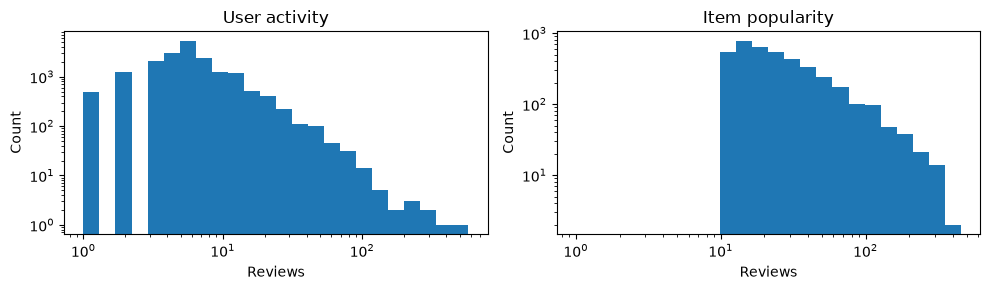

In [3]:
print('Пропуски:', raw.isna().sum().to_dict())
print('Повторы user–item:', raw.duplicated(['reviewerID', 'asin']).sum())

clean = raw.dropna()
clean = clean[clean.overall.between(1, 5) & (clean.unixReviewTime > 0)]
clean = clean.sort_values(['unixReviewTime', 'reviewerID', 'asin', 'overall'], kind='stable')
clean = clean.drop_duplicates(['reviewerID', 'asin'], keep='first')

past = clean[clean.unixReviewTime < TRAIN_END]
item_counts = past.groupby('asin').size().reset_index(name='count')
item_counts = item_counts.sort_values(['count', 'asin'], ascending=[False, True])
item_ids = sorted(item_counts.head(4000).asin)
user_ids = sorted(past[past.asin.isin(item_ids)].reviewerID.unique())

data = clean[clean.asin.isin(item_ids) & clean.reviewerID.isin(user_ids)].copy()
data['user'] = data.reviewerID.map({user: index for index, user in enumerate(user_ids)})
data['item'] = data.asin.map({item: index for index, item in enumerate(item_ids)})
shape = (len(user_ids), len(item_ids))

meta = raw_meta.drop_duplicates('asin').set_index('asin').reindex(item_ids)
activity = data.groupby('user').size()
popularity = data.groupby('item').size()

print(f'После отбора: {len(data):,} взаимодействий, {shape[0]:,} пользователей, {shape[1]:,} товаров')
print(f'Разреженность: {1 - len(data) / (shape[0] * shape[1]):.4%}')
print('Медиана отзывов на пользователя / товар:', activity.median(), '/', popularity.median())
print('Товаров без категорий:', meta.categories.isna().sum())

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, counts, title in zip(axes, [activity, popularity], ['User activity', 'Item popularity']):
    ax.hist(counts, bins=np.geomspace(1, counts.max() + 1, 25))
    ax.set(xscale='log', yscale='log', title=title, xlabel='Reviews', ylabel='Count')

plt.tight_layout()
plt.show()

Для FM добавим категории товаров: префиксы категориальных путей без общего корня.
Нормируем вектор каждого товара до L2-нормы 1. Это позволяет разделять информацию между похожими товарами.
Категории считаем статическими, хотя исторических снимков для проверки нет, цены, популярность из metadata и связи товаров не используем.

In [4]:
item_categories = []
for paths in meta.categories:
    labels = set()
    if isinstance(paths, list):
        for path in paths:
            for depth in range(2, len(path) + 1):
                labels.add(' > '.join(path[:depth]))
    item_categories.append(sorted(labels) or ['<unknown>'])

all_categories = sorted({label for labels in item_categories for label in labels})
category_index = {label: index for index, label in enumerate(all_categories)}

rows, columns, values = [], [], []
for item, labels in enumerate(item_categories):
    for label in labels:
        rows.append(item)
        columns.append(category_index[label])
        values.append(1 / np.sqrt(len(labels)))

categories = sparse.csr_matrix(
    (values, (rows, columns)),
    shape=(shape[1], len(all_categories)),
)
print('Признаков категорий:', categories.shape[1])

Признаков категорий: 306


## Разбиение и метрики
Train — до 2013 года, validation — 2013 год, test — 2014 год до конца данных.
Подбор делаем по NDCG@10 на validation, затем переобучаем модели на train+validation.
Все модели ранжируют одинаковый каталог, исключая любые ранее оценённые товары.
Новых пользователей и товары вне каталога не оцениваем, в метриках участвуют пользователи с положительным отзывом в отложенном периоде.

NDCG@10 учитывает позицию релевантного товара, Recall@10 — долю найденных релевантных товаров.
Обе метрики усредняем по пользователям:
$Recall@10=|L^{10}\cap R|/|R|$,
$NDCG@10=\frac{\sum_{j=1}^{10}[L_j\in R]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R|)}1/\log_2(j+1)}$.

In [5]:
def matrices(frame):
    coordinates = (frame.user.to_numpy(), frame.item.to_numpy())
    ratings = sparse.csr_matrix((frame.overall.to_numpy(float), coordinates), shape=shape)
    timestamps = sparse.csr_matrix((frame.unixReviewTime.to_numpy(float), coordinates), shape=shape)

    observed = ratings.copy()
    observed.data[:] = 1
    target = ratings.copy()
    target.data = (ratings.data >= 4).astype(float)
    positive = target.copy()
    positive.eliminate_zeros()

    return {
        'observed': observed,
        'ratings': ratings,
        'timestamps': timestamps,
        'target': target,
        'positive': positive,
    }


def evaluate(model, truth, seen):
    users = np.array(sorted(truth))
    discounts = 1 / np.log2(np.arange(2, 12))
    ndcg, recall = [], []

    for start in range(0, len(users), 128):
        batch = users[start:start + 128]
        recommendations = model.recommend(batch, seen, k=10)

        for user, ranking in zip(batch, recommendations):
            relevant = truth[user]
            hits = np.isin(ranking, relevant)
            ideal_dcg = discounts[:min(10, len(relevant))].sum()

            ndcg.append(np.dot(hits, discounts) / ideal_dcg)
            recall.append(hits.sum() / len(relevant))

    return {'NDCG@10': np.mean(ndcg), 'Recall@10': np.mean(recall)}


train = data[data.unixReviewTime < TRAIN_END]
validation = data[(data.unixReviewTime >= TRAIN_END) & (data.unixReviewTime < VAL_END)]
test = data[data.unixReviewTime >= VAL_END]
train_data = matrices(train)

validation_truth = validation[validation.overall >= 4].groupby('user').item.agg(list).to_dict()
test_truth = test[test.overall >= 4].groupby('user').item.agg(list).to_dict()

print('Train / validation / test:', len(train), '/', len(validation), '/', len(test))
print('Пользователей для оценки validation / test:', len(validation_truth), '/', len(test_truth))

Train / validation / test: 121195 / 11682 / 3214
Пользователей для оценки validation / test: 4074 / 1407


## Обучение пяти моделей
Реализации с нуля находятся в `models/`. Пусть $X_{ui}=[r_{ui}\ge4]$, а $O_{ui}$ отмечает любой отзыв.

- Item-kNN: $s_{ij}=X_i^TX_j/(\|X_i\|\|X_j\|+\beta)$, $s_{ii}=0$, score — сумма сходств с оценёнными положительно товарами по ближайшим соседям.
- iALS: минимизируем $\sum_{ui}(1+\alpha O_{ui})(X_{ui}-u_u^Tv_i)^2+\lambda(\|U\|^2+\|V\|^2)$ поочерёдными решениями линейных систем.
- EASE: минимизируем $\|X-XB\|^2+\lambda\|B\|^2$ при $\operatorname{diag}B=0$. Для $P=(X^TX+\lambda I)^{-1}$ имеем $B_{ij}=-P_{ij}/P_{jj}$ вне диагонали, score — $XB$.
- FM: $f(x)=b+w^Tx+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k$. Признаки — ID пользователя, ID товара и категории. Обучаем по binary cross-entropy с L2 и Adam, по два случайных train-негатива на положительный отзыв, 40 эпох.
- CustomALS: тот же ALS и confidence, но таргет $p_{ui}=(r_{ui}-3)/2\cdot2^{-(t_0-t_{ui})/(86400h)}$ для наблюдаемых пар, иначе 0. Он различает силу оценки и ослабляет старые события. Релевантность test остаётся оценкой ≥4.

Перебираем по два варианта настроек из словаря ниже. У CustomALS сохраняем выбранные параметры iALS и подбираем только полураспад $h$.

In [6]:
search = {
    'ItemKNN': [{'neighbors': 50, 'shrink': shrink} for shrink in [0, 20]],
    'iALS': [{'factors': 32, 'reg': reg, 'alpha': 20, 'iterations': 15} for reg in [1, 10]],
    'EASE': [{'reg': reg} for reg in [30, 100]],
    'FM': [{'factors': 32, 'reg': reg, 'epochs': 40} for reg in [1e-6, 1e-5]],
    'CustomALS': [{'half_life_days': days} for days in [365, 730]],
}

classes = {
    'ItemKNN': ItemKNN,
    'iALS': IALS,
    'EASE': EASE,
    'FM': FM,
    'CustomALS': CustomALS,
}


def fit_model(name, params, data, cutoff):
    model = classes[name](**params)

    if name in ['ItemKNN', 'EASE']:
        model.fit(data['positive'])
    elif name == 'iALS':
        model.fit(data['observed'], data['target'])
    elif name == 'CustomALS':
        model.fit_ratings(data['observed'], data['ratings'], data['timestamps'], cutoff)
    else:
        model.fit(data['observed'], data['ratings'], categories)

    return model


best_params = {}
for name, variants in search.items():
    best_score = -1

    for params in variants:
        if name == 'CustomALS':
            params = {**best_params['iALS'], **params}

        model = fit_model(name, params, train_data, TRAIN_END)
        score = evaluate(model, validation_truth, train_data['observed'])['NDCG@10']

        if score > best_score:
            best_score = score
            best_params[name] = params

        del model

## Сравнение
Переобучаем пять моделей с выбранными настройками на train+validation и считаем метрики на test.

In [7]:
final_data = matrices(pd.concat([train, validation], ignore_index=True))
results = []

for name, params in best_params.items():
    model = fit_model(name, params, final_data, VAL_END)
    metrics = evaluate(model, test_truth, final_data['observed'])
    results.append({'Модель': name, **metrics, 'Параметры': str(params)})
    del model

results = pd.DataFrame(results).set_index('Модель').sort_values('NDCG@10', ascending=False)
display(results.round(5))

,NDCG@10,Recall@10,Параметры
Модель,,,
CustomALS,0.04185,0.06490,"{'factors': 32, 'reg': 1, 'alpha': 20, 'iterations': 15, 'half_life_days': 365}"
iALS,0.04162,0.07267,"{'factors': 32, 'reg': 1, 'alpha': 20, 'iterations': 15}"
EASE,0.04056,0.06404,{'reg': 30}
ItemKNN,0.03351,0.05710,"{'neighbors': 50, 'shrink': 20}"
FM,0.02765,0.05148,"{'factors': 32, 'reg': 1e-05, 'epochs': 40}"


## Выводы
По основной метрике NDCG@10 первое место занял CustomALS: 0.04185, но обычный iALS почти не уступил ему — 0.04162.
При этом по Recall@10 лучше iALS: 0.07267 против 0.06490. То есть кастомный таргет дал небольшой
прирост NDCG, но снизил долю найденных релевантных товаров. Явного преимущества по обеим метрикам он не дал.
Для обеих моделей выбраны 32 фактора и регуляризация 1, для CustomALS — полураспад 365 дней.

EASE показал близкое к лидерам качество: NDCG@10 0.04056, Recall@10 0.06404 при регуляризации 30.
Item-kNN с 50 соседями и shrinkage 20 оказался слабее: 0.03351 и 0.05710 соответственно.
В этом сравнении факторизационные ALS-модели и EASE справились лучше соседского метода.

FM с категориями получила самые низкие значения: NDCG@10 0.02765, Recall@10 0.05148.
Добавление метаданных само по себе не обеспечило высокого качества. Однако отдельный вклад категорий
не измеряли: без сравнения с FM только на ID нельзя сказать, помогли они или ухудшили результат.
Вывод относится к выбранным настройкам и 40 эпохам обучения, а не к FM в целом.

Для этого разбиения iALS выглядит хорошей отправной точкой: у него максимальный Recall@10
и почти максимальный NDCG@10. Если ориентироваться строго на основную метрику, формальный победитель — CustomALS.

Результаты получены на одном временном разбиении, с одним seed и небольшим подбором параметров.
Каталог ограничен популярными товарами, новые пользователи и товары не оцениваются.
Неизменность категорий во времени предполагается, поэтому переносить эти результаты на весь каталог и другие периоды пока нельзя.